<a href="https://colab.research.google.com/github/SriVarshiniD/NIE-ML2/blob/main/ML2Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Example: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes']
S Boundary: [['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']]
G Boundary: [['?', '?', '?', '?', '?', '?']]

Example: ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes']
S Boundary: [['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']]
G Boundary: [['?', '?', '?', '?', '?', '?']]

Example: ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No']
S Boundary: [['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']]
G Boundary: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]

Example: ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']
S Boundary: [['Sunny', 'Warm', '?', 'Strong', '?', '?']]
G Boundary: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]


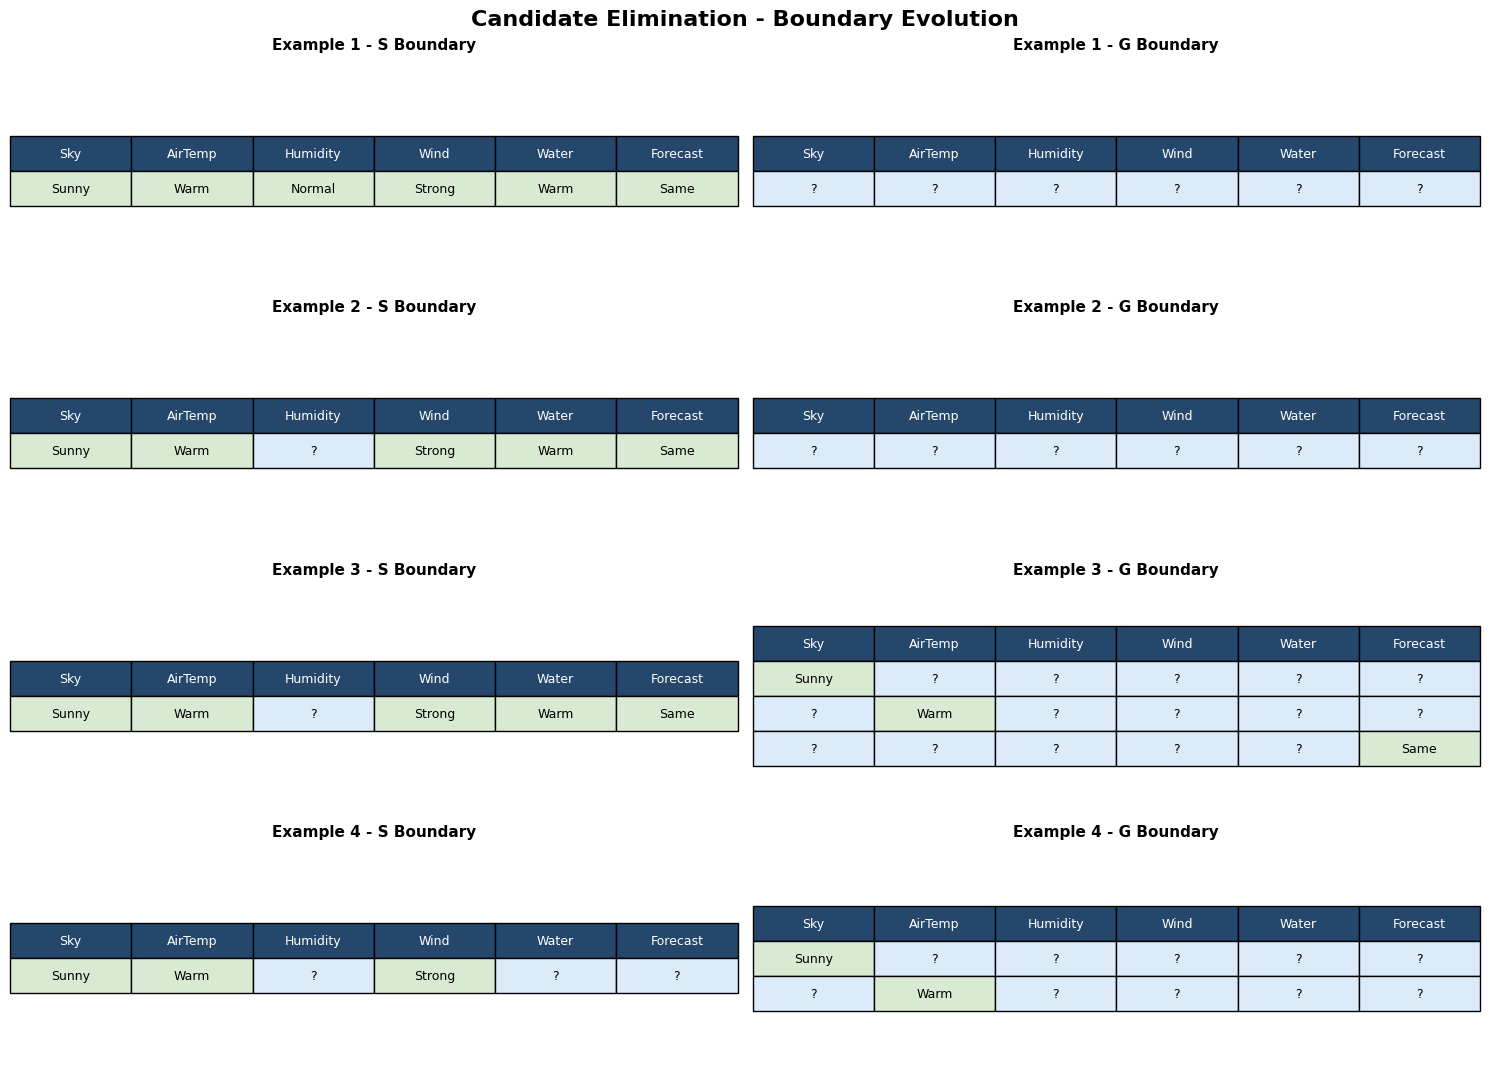

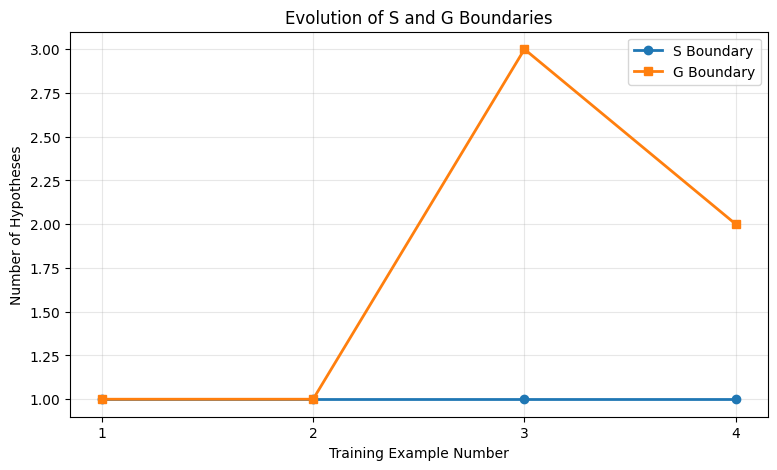


FINAL VERSION SPACE

Specific Boundary (S):
['Sunny', 'Warm', '?', 'Strong', '?', '?']

General Boundary (G):
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']


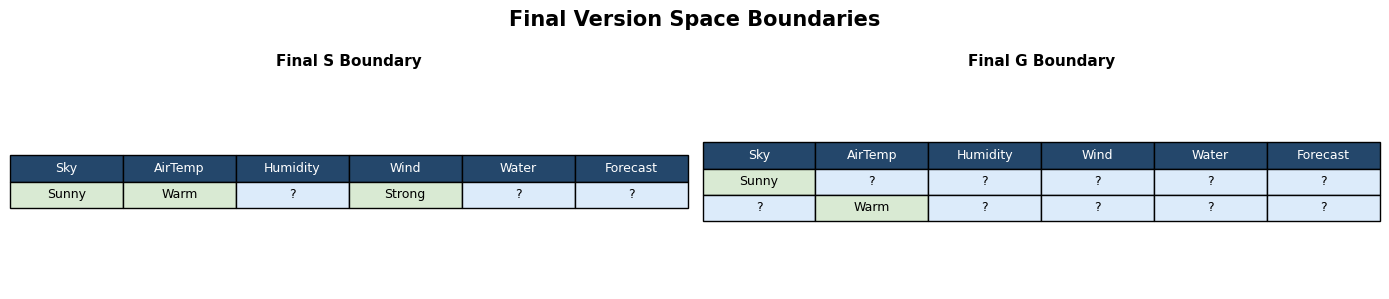

In [ ]:

import matplotlib.pyplot as plt

# --------------------------------
# 1. TRAINING DATASET
# --------------------------------

data = [
    ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes'],
    ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No'],
    ['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']
]

attributes = [
    'Sky', 'AirTemp', 'Humidity',
    'Wind', 'Water', 'Forecast'
]

n = len(attributes)

domains = [
    list(set(row[i] for row in data))
    for i in range(n)
]

# --------------------------------
# 2. INITIALIZE S AND G
# --------------------------------

S = [['Ø'] * n]
G = [['?'] * n]

history = []


# --------------------------------
# 3. HELPER FUNCTIONS
# --------------------------------

def covers(h, x):
    return all(
        h[i] == '?' or h[i] == x[i]
        for i in range(n)
    )


def more_general(h1, h2):
    return all(
        h1[i] == '?' or h1[i] == h2[i]
        for i in range(n)
    )


def remove_general(hypotheses):
    return [
        h for h in hypotheses
        if not any(
            h != other and more_general(h, other)
            for other in hypotheses
        )
    ]


def remove_specific(hypotheses):
    return [
        h for h in hypotheses
        if not any(
            h != other and more_general(other, h)
            for other in hypotheses
        )
    ]


# --------------------------------
# 4. CANDIDATE ELIMINATION
# --------------------------------

for example in data:

    x = example[:-1]
    label = example[-1]

    if label == 'Yes':

        # Positive example: Generalize S
        G = [g for g in G if covers(g, x)]

        new_S = []

        for s in S:
            if covers(s, x):
                new_S.append(s)
            else:
                h = s.copy()

                for i in range(n):
                    if h[i] == 'Ø':
                        h[i] = x[i]
                    elif h[i] != x[i]:
                        h[i] = '?'

                new_S.append(h)

        S = remove_general(new_S)

    else:

        # Negative example: Specialize G
        S = [s for s in S if not covers(s, x)]

        new_G = []

        for g in G:
            if not covers(g, x):
                new_G.append(g)
            else:
                for i in range(n):
                    if g[i] == '?':
                        for value in domains[i]:

                            if value != x[i]:
                                h = g.copy()
                                h[i] = value

                                if any(
                                    more_general(h, s)
                                    for s in S
                                ):
                                    new_G.append(h)

        G = remove_specific(new_G)

    # Save boundaries after each example
    history.append({
        'S': [h.copy() for h in S],
        'G': [h.copy() for h in G]
    })

    print("\nExample:", example)
    print("S Boundary:", S)
    print("G Boundary:", G)


# --------------------------------
# 5. VISUALIZE S AND G BOUNDARIES
# --------------------------------

def draw_boundary(ax, hypotheses, title):

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

    if not hypotheses:
        ax.text(0.5, 0.5, "Empty Boundary",
                ha='center', va='center')
        return

    table = ax.table(
        cellText=hypotheses,
        colLabels=attributes,
        cellLoc='center',
        loc='center'
    )

    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.7)

    # Color code the hypotheses
    for (row, col), cell in table.get_celld().items():

        if row == 0:
            cell.set_facecolor('#24476B')
            cell.get_text().set_color('white')

        elif col >= 0:
            value = hypotheses[row - 1][col]

            if value == '?':
                cell.set_facecolor('#DCEBFA')

            elif value == 'Ø':
                cell.set_facecolor('#E0E0E0')

            else:
                cell.set_facecolor('#D9EAD3')


# Plot boundary evolution after each example
fig, axes = plt.subplots(
    len(data), 2,
    figsize=(15, 11)
)

fig.suptitle(
    'Candidate Elimination - Boundary Evolution',
    fontsize=16,
    fontweight='bold'
)

for i, step in enumerate(history):

    draw_boundary(
        axes[i, 0],
        step['S'],
        f"Example {i+1} - S Boundary"
    )

    draw_boundary(
        axes[i, 1],
        step['G'],
        f"Example {i+1} - G Boundary"
    )

plt.tight_layout()
plt.show()


# --------------------------------
# 6. GRAPH: NUMBER OF HYPOTHESES
# --------------------------------

s_counts = [len(step['S']) for step in history]
g_counts = [len(step['G']) for step in history]

plt.figure(figsize=(9, 5))

steps = range(1, len(data) + 1)

plt.plot(
    steps, s_counts,
    marker='o',
    linewidth=2,
    label='S Boundary'
)

plt.plot(
    steps, g_counts,
    marker='s',
    linewidth=2,
    label='G Boundary'
)

plt.xlabel('Training Example Number')
plt.ylabel('Number of Hypotheses')
plt.title('Evolution of S and G Boundaries')
plt.xticks(list(steps))
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()


# --------------------------------
# 7. FINAL VERSION SPACE
# --------------------------------

print("\nFINAL VERSION SPACE")

print("\nSpecific Boundary (S):")
for h in S:
    print(h)

print("\nGeneral Boundary (G):")
for h in G:
    print(h)

# Final boundary visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

draw_boundary(axes[0], S, 'Final S Boundary')
draw_boundary(axes[1], G, 'Final G Boundary')

fig.suptitle(
    'Final Version Space Boundaries',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()
